# Atomic-representation Bayesian model for TCR–peptide cross-reactivity
### แทนที่ *amino-acid similarity matrix* ด้วย *atomic peptide representation*

**เป้าหมายงานวิจัย (Research goal).** พัฒนา Bayesian model สำหรับทำนาย **TCR cross-reactivity** (peptide ตัวไหนกระตุ้น TCR หนึ่ง ๆ) โดย **แทนที่ 20×20 amino-acid substitution/similarity matrix** ที่ใช้ใน BATMAN ด้วย **atomic peptide representation** — คือ feature ระดับอะตอม/เคมีของแต่ละ residue แล้วให้ระยะการแทนที่ (substitution distance) เป็น *ฟังก์ชันของผลต่าง feature เชิงอะตอม* ที่เรียนรู้ได้

**ตั้งต้นจากเปเปอร์.** Banerjee et al., *"T cell receptor cross-reactivity prediction improved by a comprehensive mutational scan database"*, **Cell Systems 16, 101345 (2025)**, doi:[10.1016/j.cels.2025.101345](https://doi.org/10.1016/j.cels.2025.101345) — เปเปอร์นี้เสนอฐานข้อมูล **BATCAVE** และโมเดล Bayesian ชื่อ **BATMAN**

| | BATMAN (เดิม) | โมเดลนี้ (ใหม่) |
|---|---|---|
| ระยะแทนที่ระดับ residue | เรียน 20×20 matrix `M` (~380 พารามิเตอร์) | `Σ_k θ_k·|Δφ_k|` จาก atomic features (~8–15 พารามิเตอร์) |
| Prior ของ `M` | BLOSUM100 | ไม่ต้องใช้ — ระยะมาจากเคมีของอะตอมโดยตรง |
| ตีความได้ | ยาก (ตารางตัวเลข) | ง่าย (น้ำหนักของ size / charge / polarity / aromaticity …) |
| Generalize สู่ substitution ที่ไม่เคยเห็น | ต้อง fallback ไป prior | interpolate ใน feature space ได้ (*ถ้าแกน feature ยัง identify ได้*) |
| Generalize สู่ non-canonical aa / PTM | ไม่ได้ | ได้ (ถ้ามีสูตรโครงสร้าง) |

> ### 📌 สรุปผลที่ได้จริงในสมุดเล่มนี้ (อ่านก่อน)
>
> ผลการทดลองจริง **ไม่ได้ยืนยันสมมติฐานตั้งต้นทั้งหมด** และเรารายงานตามจริง:
>
> | | ผลลัพธ์ |
> |---|---|
> | **In-distribution (5-fold CV)** | atomic 0.840 — ชนะ fixed-BLOSUM (0.824) แต่ **แพ้** learned matrix (0.883) |
> | **Leave-chemistry-out (8 feat)** | atomic ชนะ **แค่ 1 ใน 4 กลุ่ม** (ชนะขาดเฉพาะ aromatic: 0.926 vs 0.898) |
> | **หลังเติม feature hydrophobicity (9 feat)** | atomic เฉลี่ย 0.846 ≈ **เสมอ** matrix baseline (0.845) ด้วยพารามิเตอร์ **น้อยกว่า ~42 เท่า** |
>
> **ข้อสรุป:** atomic representation ให้ประสิทธิภาพ **เทียบเท่า** matrix ในการ generalize โดยใช้พารามิเตอร์น้อยกว่ามาก **ตีความได้** และ **ขยายไป non-canonical amino acid ได้** — ไม่ใช่ "ชนะขาด" แต่เป็น trade-off ที่คุ้มค่าและวินิจฉัยจุดอ่อนต่อได้ (ดูหัวข้อ 8.1–8.2 และ 10.3)


## 1. พื้นหลังและช่องว่างงานวิจัย (Background & gap)

TCR หนึ่งตัวจับ (recognize) peptide ได้หลายชนิด = **cross-reactivity** สำคัญมากต่อการทำนาย viral escape, neoantigen immunogenicity, autoimmunity และ off-target toxicity ของ TCR-therapy

**BATMAN** ทำนาย activation level ของ TCR ต่อ peptide กลายพันธุ์ (single-amino-acid mutant) จาก *ระยะทาง* ของ peptide ไปยัง **index peptide** (peptide ที่ TCR จับแรงที่สุด) โดย

$$d(\text{peptide},\text{index}) = \sum_{\text{position } j} w_j \cdot M\big[a_{\text{index},j},\, a_{\text{peptide},j}\big]$$

- $w_j$ = **positional weight** (ตำแหน่งไหนใน peptide สำคัญต่อ TCR นี้) — เรียนแบบ TCR-specific
- $M[a,b]$ = **20×20 amino-acid substitution distance matrix** — เรียนร่วมกัน โดยมี BLOSUM100 เป็น prior

**ปัญหาของ `M` (นี่คือช่องว่างที่งานนี้จะแก้):**
1. **พารามิเตอร์เยอะ (~380 ช่อง off-diagonal)** → กินข้อมูล, เสี่ยง overfit โดยเฉพาะโหมด leave-one-TCR-out
2. **Extrapolate ไม่ได้** — ถ้า substitution คู่ `(a→b)` ไม่เคยอยู่ใน training, `M[a,b]` ก็ได้แค่ค่า prior
3. **ผูกกับ 20 residue มาตรฐาน** — ใช้กับ non-canonical amino acid / post-translational modification ไม่ได้
4. **ตีความยาก** — ตารางตัวเลข ไม่บอกว่า *ทำไม* สอง residue ถึงคล้าย/ต่างกัน

**ไอเดียของงานนี้:** แทน `M[a,b]` ด้วยฟังก์ชันของ **atomic representation** $\phi(a)$ (เวกเตอร์ feature เชิงอะตอม/เคมีของ side chain):

$$M[a,b] \;=\; \sum_{k=1}^{K} \theta_k \,\big|\phi_k(a) - \phi_k(b)\big|,\qquad \theta_k \ge 0$$

เป็น **weighted city-block (Manhattan) distance** ใน atomic feature space โดยเรียนแค่ $\theta \in \mathbb{R}^K$ (K≈8–15). รูปนี้ทำให้ $M[a,a]=0$ และ $M[a,b]\ge 0$ โดยอัตโนมัติ (เป็น distance ที่ถูกต้อง) และ **ตีความได้ทันที** ว่า TCR ไวต่อการเปลี่ยนคุณสมบัติเชิงอะตอมด้านใด


## 2. ติดตั้งไลบรารี (Setup)

รันครั้งเดียว หากยังไม่มี package ปลดคอมเมนต์บรรทัด `pip` ด้านล่าง

In [1]:
# !pip install pymc arviz rdkit scikit-learn biopython pandas numpy matplotlib openpyxl
import numpy as np, pandas as pd, warnings, os, time, urllib.request
warnings.filterwarnings("ignore")
import pymc as pm, pytensor.tensor as pt, arviz as az
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors, Draw
from Bio.Align import substitution_matrices
RNG = np.random.default_rng(0)
print("pymc", pm.__version__, "| numpy", np.__version__)

pymc 6.3.1 | numpy 2.4.2


## 3. ดาวน์โหลด / clone ชุดข้อมูล BATCAVE

ข้อมูลมาจาก repository ของเปเปอร์: **`meyer-lab-cshl/BATMAN-paper`** (Zenodo: [10.5281/zenodo.15318036](https://doi.org/10.5281/zenodo.15318036))

**ตัวเลือก A — clone ทั้ง repo (แนะนำถ้าต้องการข้อมูลดิบครบ):**
```bash
git clone https://github.com/meyer-lab-cshl/BATMAN-paper.git
# ฐานข้อมูลอยู่ที่:
#   BATMAN-paper/results_batman/tcr_epitope_datasets/mutational_scan_datasets/
#     ├── database/TCR_pMHCI_mutational_scan_database.xlsx      (MHC class I)
#     ├── database/TCR_pMHCII_mutational_scan_database.xlsx     (MHC class II)
#     └── train_test_data_folds.xlsx   <-- ไฟล์พร้อมใช้ (มี activation label + fold + NetMHCpan)
```

**ตัวเลือก B — clone เฉพาะโฟลเดอร์ข้อมูล (sparse checkout, เบากว่า):**
```bash
git clone --no-checkout --depth 1 https://github.com/meyer-lab-cshl/BATMAN-paper.git
cd BATMAN-paper
git sparse-checkout init --cone
git sparse-checkout set results_batman/tcr_epitope_datasets/mutational_scan_datasets
git checkout main
```

**ตัวเลือก C — โหลดไฟล์เดียวตรง ๆ (สมุดเล่มนี้ใช้อันนี้ให้อัตโนมัติ):** เซลล์ถัดไปจะดึง `train_test_data_folds.xlsx` มาให้เลย

> ไฟล์ `train_test_data_folds.xlsx` คือ **BATCAVE เวอร์ชันประมวลผลแล้ว**: 22,827 แถว, 151 TCR, 25 index peptide พร้อมคอลัมน์ `activation` (0=non / 1=weak / 2=strong), `mutation_position`, `training_fold` (0–4) และผลทำนาย pMHC-binding จาก NetMHCpan

In [2]:
# --- โหลดข้อมูล (ตัวเลือก C): พยายามอ่านจาก local clone ก่อน ถ้าไม่มีค่อยดาวน์โหลด ---
RAW = ("https://raw.githubusercontent.com/meyer-lab-cshl/BATMAN-paper/main/"
       "results_batman/tcr_epitope_datasets/mutational_scan_datasets/train_test_data_folds.xlsx")
LOCAL_CANDIDATES = [
    "BATMAN-paper/results_batman/tcr_epitope_datasets/mutational_scan_datasets/train_test_data_folds.xlsx",
    "data/train_test_data_folds.xlsx",
    "train_test_data_folds.xlsx",
]
path = next((p for p in LOCAL_CANDIDATES if os.path.exists(p)), None)
if path is None:
    os.makedirs("data", exist_ok=True)
    path = "data/train_test_data_folds.xlsx"
    print("downloading BATCAVE ...")
    urllib.request.urlretrieve(RAW, path)
print("using:", path)
data = pd.read_excel(path)
print("shape:", data.shape)
data[["tcr","index_peptide","peptide","peptide_activity","activation",
      "mutation_position","mhc","training_fold"]].head()

using: data/train_test_data_folds.xlsx


shape: (22827, 26)


,tcr,index_peptide,peptide,peptide_activity,activation,mutation_position,mhc,training_fold
0,TCR-F5,FRDYVDRFYKTLRAEQASQE,ARDYVDRFYKTLRAEQASQE,0.833465,2,1,HLA-DRB1*11:01,1.0
1,TCR-F5,FRDYVDRFYKTLRAEQASQE,CRDYVDRFYKTLRAEQASQE,0.696343,2,1,HLA-DRB1*11:01,2.0
2,TCR-F5,FRDYVDRFYKTLRAEQASQE,DRDYVDRFYKTLRAEQASQE,0.708967,2,1,HLA-DRB1*11:01,3.0
3,TCR-F5,FRDYVDRFYKTLRAEQASQE,ERDYVDRFYKTLRAEQASQE,0.881440,2,1,HLA-DRB1*11:01,3.0
4,TCR-F5,FRDYVDRFYKTLRAEQASQE,FRDYVDRFYKTLRAEQASQE,0.657481,2,0,HLA-DRB1*11:01,NaN


In [3]:
# --- ภาพรวมชุดข้อมูล ---
print("จำนวน TCR              :", data.tcr.nunique())
print("จำนวน index peptide    :", data.index_peptide.nunique())
print("ความยาว index peptide  :", sorted(data.index_peptide.str.len().unique()))
print("การกระจาย activation   :", data.activation.value_counts().sort_index().to_dict(),
      "  (0=non,1=weak,2=strong)")
grp = (data.assign(L=data.index_peptide.str.len())
           .groupby("L").agg(n_rows=("tcr","size"), n_tcr=("tcr","nunique")))
print("\nข้อมูลแยกตามความยาว peptide:")
print(grp)

จำนวน TCR              : 151
จำนวน index peptide    : 25
ความยาว index peptide  : [np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(13), np.int64(20)]
การกระจาย activation   : {0: 9161, 1: 5838, 2: 7828}   (0=non,1=weak,2=strong)

ข้อมูลแยกตามความยาว peptide:
    n_rows  n_tcr
L                
8     5202     34
9    10348     62
10    1337      7
11     420      2
13    3996     42
20    1524      4


## 4. Atomic peptide representation

เราสร้าง feature ระดับอะตอมของแต่ละ residue จาก **โครงสร้างเคมีจริง** ด้วย RDKit โดยเริ่มจาก SMILES ของกรดอะมิโนทั้ง 20 ตัว แล้วนับ/คำนวณ descriptor เชิงอะตอม จากนั้น **ลบค่าของ glycine (backbone ล้วน)** เพื่อแยกเอาเฉพาะส่วน **side chain** (เพราะ backbone เหมือนกันหมด ผลของการกลายพันธุ์อยู่ที่ side chain)

Feature ที่เลือก (กระชับ ตีความง่าย ไม่ซ้ำซ้อนกันมาก):

| feature | ความหมายเชิงอะตอม |
|---|---|
| `heavy` | จำนวน heavy atom ของ side chain → **ขนาด/สเตอริก** |
| `polar`  | จำนวนอะตอม N+O → **ความมีขั้ว / hydrogen-bonding** |
| `S`      | จำนวนอะตอมกำมะถัน (Cys, Met) |
| `aromatic` | จำนวนอะตอมในวงอะโรมาติก → **π-stacking** |
| `HBD` / `HBA` | จำนวน H-bond donor / acceptor |
| `rotB`   | rotatable bonds → **ความยืดหยุ่น (flexibility)** |
| `charge` | ประจุสุทธิที่ pH 7 (D,E = −1; K,R = +1; H = +0.1) |

> `charge` เป็น physicochemical property ที่จำเป็นและ *ไม่* ได้มาจากการนับอะตอมของฟอร์มเป็นกลาง จึงใส่เพิ่มเข้ามา — เป็นตัวแปรสำคัญต่อ TCR–pMHC electrostatics

In [4]:
# SMILES (neutral, ทั้งกรดอะมิโน) ของ 20 residue มาตรฐาน
AA_SMILES = {
 'A':'CC(N)C(=O)O','R':'NC(CCCNC(=N)N)C(=O)O','N':'NC(CC(=O)N)C(=O)O','D':'NC(CC(=O)O)C(=O)O',
 'C':'NC(CS)C(=O)O','Q':'NC(CCC(=O)N)C(=O)O','E':'NC(CCC(=O)O)C(=O)O','G':'NCC(=O)O',
 'H':'NC(Cc1cnc[nH]1)C(=O)O','I':'CCC(C)C(N)C(=O)O','L':'CC(C)CC(N)C(=O)O','K':'NCCCCC(N)C(=O)O',
 'M':'CSCCC(N)C(=O)O','F':'NC(Cc1ccccc1)C(=O)O','P':'OC(=O)C1CCCN1','S':'NC(CO)C(=O)O',
 'T':'CC(O)C(N)C(=O)O','W':'NC(Cc1c[nH]c2ccccc12)C(=O)O','Y':'NC(Cc1ccc(O)cc1)C(=O)O','V':'CC(C)C(N)C(=O)O'}
CHARGE = dict(D=-1.0, E=-1.0, K=1.0, R=1.0, H=0.1)   # ประจุที่ pH 7

def count_atom(mol, sym):
    return sum(1 for a in mol.GetAtoms() if a.GetSymbol() == sym)

recs = []
for aa, smi in AA_SMILES.items():
    m = Chem.MolFromSmiles(smi)
    recs.append(dict(aa=aa,
        heavy = m.GetNumHeavyAtoms(),
        polar = count_atom(m,'N') + count_atom(m,'O'),
        S     = count_atom(m,'S'),
        aromatic = sum(1 for a in m.GetAtoms() if a.GetIsAromatic()),
        HBD = rdMolDescriptors.CalcNumHBD(m),
        HBA = rdMolDescriptors.CalcNumHBA(m),
        rotB = rdMolDescriptors.CalcNumRotatableBonds(m),
        charge = CHARGE.get(aa, 0.0)))
feat_raw = pd.DataFrame(recs).set_index("aa")

# ลบ backbone (glycine) เพื่อแยก side chain สำหรับ feature ที่เป็นการนับ
additive = ['heavy','polar','S','HBD','HBA','rotB']
feat_sc = feat_raw.copy()
for c in additive:
    feat_sc[c] = feat_raw[c] - feat_raw.loc['G', c]

FEATURES = ['heavy','polar','S','aromatic','HBD','HBA','rotB','charge']
feat_sc = feat_sc[FEATURES]
feat_sc.round(2)

,heavy,polar,S,aromatic,HBD,HBA,rotB,charge
aa,,,,,,,,
A,1,0,0,0,0,0,0,0.0
R,7,3,0,0,3,1,4,1.0
N,4,2,0,0,1,1,2,0.0
D,4,2,0,0,1,1,2,-1.0
C,2,0,1,0,1,1,1,0.0
Q,5,2,0,0,1,1,3,0.0
E,5,2,0,0,1,1,3,-1.0
G,0,0,0,0,0,0,0,0.0
H,6,2,0,5,1,1,2,0.1


atomic feature matrix Phi: (20, 8) | features: ['heavy', 'polar', 'S', 'aromatic', 'HBD', 'HBA', 'rotB', 'charge']


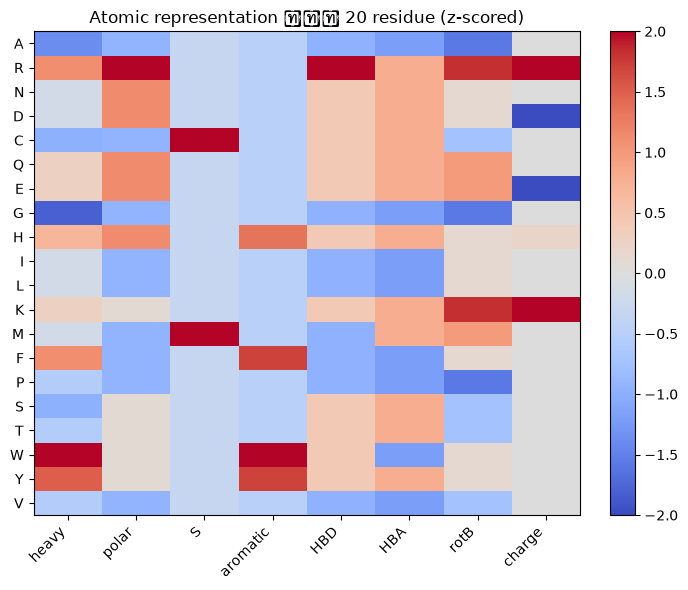

In [5]:
# standardize (z-score) เพื่อให้ทุก feature มีสเกลเทียบเท่ากันก่อนเข้าโมเดล
Phi = (feat_sc - feat_sc.mean()) / feat_sc.std()
AA_LIST = list(Phi.index)
AA_IDX  = {a:i for i,a in enumerate(AA_LIST)}
PHI = Phi.values.astype(float)          # (20, K)
K = len(FEATURES)
print("atomic feature matrix Phi:", PHI.shape, "| features:", FEATURES)

# ภาพ: heatmap ของ atomic representation
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(Phi.values, aspect='auto', cmap='coolwarm', vmin=-2, vmax=2)
ax.set_xticks(range(K)); ax.set_xticklabels(FEATURES, rotation=45, ha='right')
ax.set_yticks(range(20)); ax.set_yticklabels(AA_LIST)
ax.set_title("Atomic representation ของ 20 residue (z-scored)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

## 5. โครงสร้างโมเดล Bayesian (hierarchical ordered-logistic)

เก็บโครงหลักของ BATMAN ไว้ทุกอย่าง เปลี่ยนแค่ *วิธีคำนวณ* `M`:

**Likelihood (ordered logistic, 3 ระดับ):** ให้ $\eta = d_0 - d$ แล้ว
$$P(a{=}\text{non}) = 1-\sigma(\eta-c_1),\quad
P(a{=}\text{weak}) = \sigma(\eta-c_1)-\sigma(\eta-c_2),\quad
P(a{=}\text{strong}) = \sigma(\eta-c_2)$$
โดย $\sigma$ = logistic, cutpoints $c_1<c_2$

**ระยะ peptide→index:** $\displaystyle d = \sum_j w_{j,\text{TCR}}\, M[a_{\text{idx},j}, a_{\text{pep},j}]$

**Priors (hierarchical):**
$$w_{j,\text{TCR}} \sim \text{Beta}(\alpha,\beta),\quad \alpha,\beta\sim\text{Gamma}(2,2),\quad d_0\sim\mathcal N(0,2),\quad c_{1,2}\sim\mathcal N(0,2)\ \text{(ordered)}$$

**ส่วนที่เปลี่ยน — นิยามของ `M` มี 3 แบบให้เทียบ:**

| โมเดล | นิยาม `M[a,b]` | #พารามิเตอร์ของ M |
|---|---|---|
| **(1) Fixed matrix** | ค่าคงที่จาก BLOSUM (Eq.24 ของเปเปอร์) | 0 |
| **(2) Learned matrix (BATMAN)** | $D[a,b]\,(1+\delta_{ab})$, $\delta\sim\mathcal N(\mu,\sigma)$ | ~380 |
| **(3) Atomic (งานนี้)** | $\sum_k \theta_k|\phi_k(a)-\phi_k(b)|$, $\theta_k\sim\text{HalfNormal}$ | K (~8) |

ทั้งสามแบบใช้ positional weight $w$, intercept, cutpoints เหมือนกันหมด — ต่างกันแค่บล็อก `M`

In [6]:
# ---- เตรียม distance matrix ตั้งต้น D จาก BLOSUM90 (Eq.24 ของเปเปอร์) ----
# หมายเหตุ: เปเปอร์ใช้ BLOSUM100; biopython มีถึง BLOSUM90 จึงใช้ตัวนี้แทน (ใกล้เคียง)
_bl = substitution_matrices.load("BLOSUM90")
Dmat = np.zeros((20,20))
for i,a in enumerate(AA_LIST):
    for j,b in enumerate(AA_LIST):
        Dmat[i,j] = (1 - _bl[a,b]/_bl[a,a]) * (1 - _bl[b,a]/_bl[b,b])
np.fill_diagonal(Dmat, 0.0)
print("BLOSUM90-derived distance matrix D:", Dmat.shape, " (ใช้เป็น baseline และ prior ของ learned-matrix)")

BLOSUM90-derived distance matrix D: (20, 20)  (ใช้เป็น baseline และ prior ของ learned-matrix)


### 5.1 ฟังก์ชันเตรียมข้อมูลและสร้างโมเดล

`prepare_arrays` แปลง DataFrame เป็น array ที่โมเดลใช้:
- `idxI`, `idxP` : ดัชนี residue (0–19) ของ index และ peptide ทุกตำแหน่ง (n × L)
- `Dabs` : เทนเซอร์ $|\phi(a_{\text{idx}})-\phi(a_{\text{pep}})|$ ต่อ (แถว, ตำแหน่ง, feature) — ใช้กับโมเดล atomic
- `y` : activation (0/1/2), `tcr_i` : ดัชนี TCR

In [7]:
def prepare_arrays(df, L, phi=None):
    '''phi = atomic feature matrix (20,K); ถ้าไม่ระบุใช้ PHI ตัวหลัก'''
    phi = PHI if phi is None else phi
    k_loc = phi.shape[1]
    df = df.reset_index(drop=True)
    idxI = np.array([[AA_IDX[c] for c in s] for s in df.index_peptide])   # (n,L)
    idxP = np.array([[AA_IDX[c] for c in s] for s in df.peptide])         # (n,L)
    n = len(df)
    Dabs = np.zeros((n, L, k_loc))
    diff = (idxI != idxP)
    for r in range(n):
        for p in range(L):
            if diff[r,p]:
                Dabs[r,p] = np.abs(phi[idxI[r,p]] - phi[idxP[r,p]])
    y = df.activation.values.astype(int)
    return idxI, idxP, Dabs, y

ORD = pm.distributions.transforms.ordered

def build_model(kind, idxI, idxP, Dabs, y, tcr_i, nT, L):
    '''kind in {"fixed","learned","atomic"} — โครงเหมือนกัน ต่างแค่บล็อก M'''
    with pm.Model() as model:
        a = pm.Gamma("a", 2, 2); b = pm.Gamma("b", 2, 2)
        w = pm.Beta("w", a, b, shape=(nT, L))                 # positional weights ต่อ TCR
        d0  = pm.Normal("d0", 0, 2)
        cut = pm.Normal("cut", 0, 2, shape=2, transform=ORD, initval=np.array([-1.,1.]))
        if kind == "fixed":
            Mrp = pt.as_tensor(Dmat[idxI, idxP])                          # (n,L) คงที่
        elif kind == "learned":
            mu = pm.Normal("mu", 0, 0.5); sig = pm.Exponential("sig", 1.0)
            delta = pm.Normal("delta", mu, sig, shape=(20,20))
            Mfull = pt.as_tensor(Dmat) * (1 + delta)
            Mrp = Mfull[idxI, idxP]                                       # (n,L)
        elif kind == "atomic":
            theta = pm.HalfNormal("theta", 1.0, shape=Dabs.shape[2])                 # น้ำหนัก atomic feature (>=0)
            Mrp = pt.tensordot(pt.as_tensor(Dabs), theta, axes=[[2],[0]]) # (n,L)
        else:
            raise ValueError(kind)
        d = pt.sum(w[tcr_i] * Mrp, axis=1)                               # (n,)
        pm.OrderedLogistic("obs", eta=d0 - d, cutpoints=cut, observed=y)
    return model

def fit_advi(model, n_iter=12000, lr=0.05, draws=300, seed=0):
    with model:
        approx = pm.fit(n_iter, method="advi", progressbar=False,
                        obj_optimizer=pm.adam(learning_rate=lr),
                        random_seed=seed)
    return approx, approx.sample(draws)

def predict_distance(kind, post, idxI, idxP, Dabs, tcr_i):
    '''คำนวณระยะ d จาก posterior mean เพื่อทำนายบน test set'''
    wm = post.posterior["w"].mean(("chain","draw")).values               # (nT,L)
    if kind == "fixed":
        Mrp = Dmat[idxI, idxP]
    elif kind == "learned":
        dl = post.posterior["delta"].mean(("chain","draw")).values
        Mrp = (Dmat*(1+dl))[idxI, idxP]
    elif kind == "atomic":
        th = post.posterior["theta"].mean(("chain","draw")).values
        Mrp = np.tensordot(Dabs, th, axes=[[2],[0]])
    return (wm[tcr_i] * Mrp).sum(1)                                      # d (สูง=activation ต่ำ)

def mean_pairwise_auc(y_true, d):
    '''เฉลี่ย AUC แบบ one-vs-one 3 คู่ (non/weak/strong) ใช้ -d เป็นคะแนน (d สูง=activation ต่ำ)'''
    score = -d
    aucs = []
    for lo, hi in [(0,1),(0,2),(1,2)]:
        m = np.isin(y_true, [lo,hi])
        if m.sum() > 3 and len(np.unique(y_true[m])) == 2:
            aucs.append(roc_auc_score((y_true[m]==hi).astype(int), score[m]))
    return float(np.mean(aucs)) if aucs else np.nan

print("helpers พร้อมใช้งาน: prepare_arrays / build_model / fit_advi / predict_distance / mean_pairwise_auc")

helpers พร้อมใช้งาน: prepare_arrays / build_model / fit_advi / predict_distance / mean_pairwise_auc


## 6. เลือกกลุ่มข้อมูลสำหรับการทดลอง

เพื่อความชัดเจนและรันได้ในเวลาเหมาะสม เราโฟกัสกลุ่ม **9-mer MHC-I TCR** (กลุ่มใหญ่ที่สุดในฐานข้อมูล และเป็นกลุ่มที่เปเปอร์ใช้ pooling) ปรับ `N_TCRS` / `ADVI_ITERS` เพื่อสเกลได้ตามต้องการ

In [8]:
# ---------------- CONFIG ----------------
PEP_LEN    = 9        # ความยาว index peptide ที่โฟกัส
N_TCRS     = 10       # จำนวน TCR (เรียงตามจำนวนข้อมูลมาก->น้อย); เพิ่มเพื่อผลนิ่งขึ้น
ADVI_ITERS = 12000    # จำนวน iteration ของ ADVI
# ----------------------------------------

sub = data[(data.index_peptide.str.len()==PEP_LEN) & (data.peptide.str.len()==PEP_LEN)].copy()
valid = (sub.peptide.apply(lambda s: all(c in AA_IDX for c in s)) &
         sub.index_peptide.apply(lambda s: all(c in AA_IDX for c in s)))
sub = sub[valid]
top_tcrs = sub.tcr.value_counts().index[:N_TCRS].tolist()
sub = sub[sub.tcr.isin(top_tcrs)].reset_index(drop=True)
TCR_I = {t:i for i,t in enumerate(sorted(sub.tcr.unique()))}
sub["tcr_i"] = sub.tcr.map(TCR_I)
nT, L = len(TCR_I), PEP_LEN
print(f"เลือก {nT} TCR | {len(sub)} แถว | index peptides: {sub.index_peptide.nunique()} ตัว")
print("การกระจาย activation:", sub.activation.value_counts().sort_index().to_dict())

เลือก 10 TCR | 1720 แถว | index peptides: 2 ตัว
การกระจาย activation: {0: 1241, 1: 252, 2: 227}


## 7. การทดลองที่ 1 — เปรียบเทียบแบบ 5-fold cross-validation (in-distribution)

ใช้คอลัมน์ `training_fold` (0–4) ที่เปเปอร์เตรียมไว้ ในแต่ละ fold: เทรนบน 4 fold + แถว index peptide (mutation_position=0, ระยะ=0) แล้วทดสอบบน fold ที่เหลือ วัดด้วย **mean pairwise AUC** เทียบ 3 โมเดล

In [9]:
idxI_all, idxP_all, Dabs_all, y_all = prepare_arrays(sub, L)
tcr_all = sub.tcr_i.values
fold    = sub.training_fold.values
is_index = (sub.mutation_position.values == 0)      # index peptide -> อยู่ใน train เสมอ

KINDS = ["fixed","learned","atomic"]
LABEL = {"fixed":"(1) Fixed BLOSUM90","learned":"(2) Learned 20x20 (BATMAN)","atomic":"(3) Atomic (proposed)"}
results = {k: [] for k in KINDS}

t_start = time.time()
for f in range(5):
    test_m  = (fold == f)
    train_m = (~test_m) | is_index
    tr, te = np.where(train_m)[0], np.where(test_m)[0]
    for kind in KINDS:
        model = build_model(kind, idxI_all[tr], idxP_all[tr], Dabs_all[tr], y_all[tr],
                            tcr_all[tr], nT, L)
        _, post = fit_advi(model, n_iter=ADVI_ITERS, seed=f)
        d_te = predict_distance(kind, post, idxI_all[te], idxP_all[te], Dabs_all[te], tcr_all[te])
        auc  = mean_pairwise_auc(y_all[te], d_te)
        results[kind].append(auc)
    print(f"fold {f}: " + " | ".join(f"{LABEL[k].split()[0]} {results[k][-1]:.3f}" for k in KINDS))
print(f"\nเสร็จใน {time.time()-t_start:.0f}s")

Finished [100%]: Average Loss = 958.84


Finished [100%]: Average Loss = 835.09


Finished [100%]: Average Loss = 874.01


fold 0: (1) 0.833 | (2) 0.882 | (3) 0.841


Finished [100%]: Average Loss = 939.1


...

fold 3: (1) 0.837 | (2) 0.903 | (3) 0.865


Finished [100%]: Average Loss = 1,019.2


Finished [100%]: Average Loss = 889.53


Finished [100%]: Average Loss = 937.25


fold 4: (1) 0.828 | (2) 0.903 | (3) 0.857

เสร็จใน 72s


=== Experiment 1: 5-fold CV (in-distribution) ===


,mean_AUC,std_AUC,n_params(M),n_params(รวม)
model,,,,
(1) Fixed BLOSUM90,0.824,0.011,0,90
(2) Learned 20x20 (BATMAN),0.883,0.018,~380,490
(3) Atomic (proposed),0.840,0.020,8,98


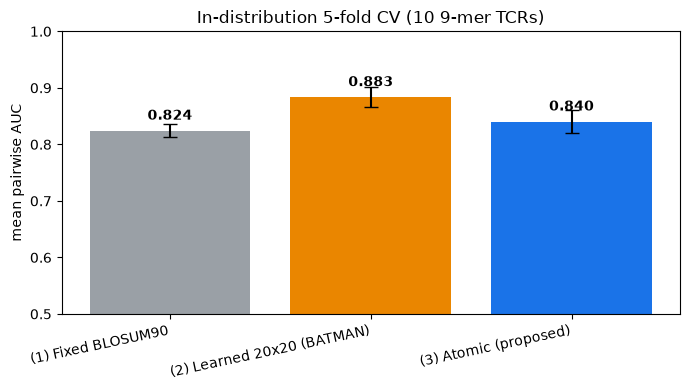

In [10]:
# สรุปผล Experiment 1
n_params = {"fixed": nT*L, "learned": nT*L+400, "atomic": nT*L+K}
summary = pd.DataFrame({
    "model":       [LABEL[k] for k in KINDS],
    "mean_AUC":    [np.mean(results[k]) for k in KINDS],
    "std_AUC":     [np.std(results[k])  for k in KINDS],
    "n_params(M)": ["0","~380",f"{K}"],
    "n_params(รวม)":[n_params[k] for k in KINDS],
}).set_index("model")
print("=== Experiment 1: 5-fold CV (in-distribution) ===")
display(summary.round(3))

fig, ax = plt.subplots(figsize=(7,4))
xs = np.arange(len(KINDS))
means = [np.mean(results[k]) for k in KINDS]; stds=[np.std(results[k]) for k in KINDS]
bars = ax.bar(xs, means, yerr=stds, capsize=5,
              color=["#9aa0a6","#ea8600","#1a73e8"])
ax.set_xticks(xs); ax.set_xticklabels([LABEL[k] for k in KINDS], rotation=12, ha="right")
ax.set_ylabel("mean pairwise AUC"); ax.set_ylim(0.5,1.0)
ax.set_title(f"In-distribution 5-fold CV ({nT} 9-mer TCRs)")
for x,m in zip(xs,means): ax.text(x,m+0.02,f"{m:.3f}",ha="center",fontweight="bold")
plt.tight_layout(); plt.show()

## 8. การทดลองที่ 2 — Leave-chemistry-out: generalization สู่ substitution ที่ไม่เคยเห็น ⭐

นี่คือ **การทดลองหัวใจ** ที่ทดสอบข้ออ้างหลักของงานนี้โดยตรง

**วิธี:** เลือกกลุ่ม residue ตามคุณสมบัติเคมี แล้ว **กันแถวที่กลายพันธุ์ไปเป็น residue กลุ่มนั้นออกจาก training ทั้งหมด** ใช้เป็น test set แทน — จำลองสถานการณ์เจอเคมีที่ไม่เคยมีในข้อมูลเทรน

เราทดสอบ **4 กลุ่ม** เพื่อไม่ให้เป็นการเลือกเฉพาะกลุ่มที่ได้ผลดี (cherry-picking):

| กลุ่ม | residues | แกน atomic ที่เกี่ยวข้อง |
|---|---|---|
| aromatic | W, F, Y | `aromatic`, `heavy` |
| charged | D, E, K, R | `charge` |
| aliphatic | I, L, V, M | `heavy`, `rotB` |
| small | A, G, S, T | `heavy` (ค่าต่ำ) |

**สมมติฐาน:** learned matrix จะเสียเปรียบเพราะช่อง `M[·,b]` ของ residue ที่ถูกกันออกไม่เคยเห็นข้อมูล ต้อง fallback ไป prior ส่วน atomic ควร interpolate ได้จาก feature space

> ⚠️ **ผลจริงจะซับซ้อนกว่าสมมติฐาน** — ดูการตีความหลังตาราง ซึ่งเป็นบทเรียนสำคัญของงานวิจัยนี้

In [11]:
# ---- Leave-chemistry-out benchmark: 4 กลุ่ม x 3 โมเดล ----
HELDOUT_GROUPS = {
    "aromatic (W/F/Y)"  : set("WFY"),
    "charged (D/E/K/R)" : set("DEKR"),
    "aliphatic (I/L/V/M)": set("ILVM"),
    "small (A/G/S/T)"   : set("AGST"),
}
mut_pos = sub.mutation_position.values.astype(int)
mut_aa  = np.array(['-' if mp==0 else sub.peptide.values[r][mp-1] for r,mp in enumerate(mut_pos)])

gen_rows, theta_store = [], {}
for gname, held in HELDOUT_GROUPS.items():
    test_m  = np.array([m in held for m in mut_aa])       # test = mutant อยู่ในกลุ่มที่กันออก
    train_m = (~test_m) & (mut_pos > 0)                    # train = single-mutant นอกกลุ่ม
    tr, te  = np.where(train_m)[0], np.where(test_m)[0]
    row = {"held-out group": gname, "n_test": len(te)}
    for kind in KINDS:
        model = build_model(kind, idxI_all[tr], idxP_all[tr], Dabs_all[tr],
                            y_all[tr], tcr_all[tr], nT, L)
        _, post = fit_advi(model, n_iter=ADVI_ITERS, seed=0)
        d_te = predict_distance(kind, post, idxI_all[te], idxP_all[te], Dabs_all[te], tcr_all[te])
        row[LABEL[kind]] = mean_pairwise_auc(y_all[te], d_te)
        if kind == "atomic":
            theta_store[gname] = post.posterior["theta"].mean(("chain","draw")).values
    gen_rows.append(row)
    print(f"{gname:22s} n_test={len(te):4d} | " +
          " | ".join(f"{LABEL[k].split(') ')[1][:12]:12s} {row[LABEL[k]]:.3f}" for k in KINDS))

gen_df = pd.DataFrame(gen_rows).set_index("held-out group")
print("\n=== Experiment 2: leave-chemistry-out ===")
display(gen_df.round(3))

Finished [100%]: Average Loss = 1,035.9


Finished [100%]: Average Loss = 897.39


Finished [100%]: Average Loss = 964.51


aromatic (W/F/Y)       n_test= 270 | Fixed BLOSUM 0.898 | Learned 20x2 0.889 | Atomic (prop 0.926


Finished [100%]: Average Loss = 973.83


...

Finished [100%]: Average Loss = 944.03


Finished [100%]: Average Loss = 824.32


Finished [100%]: Average Loss = 858.33


small (A/G/S/T)        n_test= 340 | Fixed BLOSUM 0.801 | Learned 20x2 0.822 | Atomic (prop 0.818

=== Experiment 2: leave-chemistry-out ===


,n_test,(1) Fixed BLOSUM90,(2) Learned 20x20 (BATMAN),(3) Atomic (proposed)
held-out group,,,,
aromatic (W/F/Y),270,0.898,0.889,0.926
charged (D/E/K/R),352,0.852,0.844,0.824
aliphatic (I/L/V/M),326,0.804,0.807,0.765
small (A/G/S/T),340,0.801,0.822,0.818


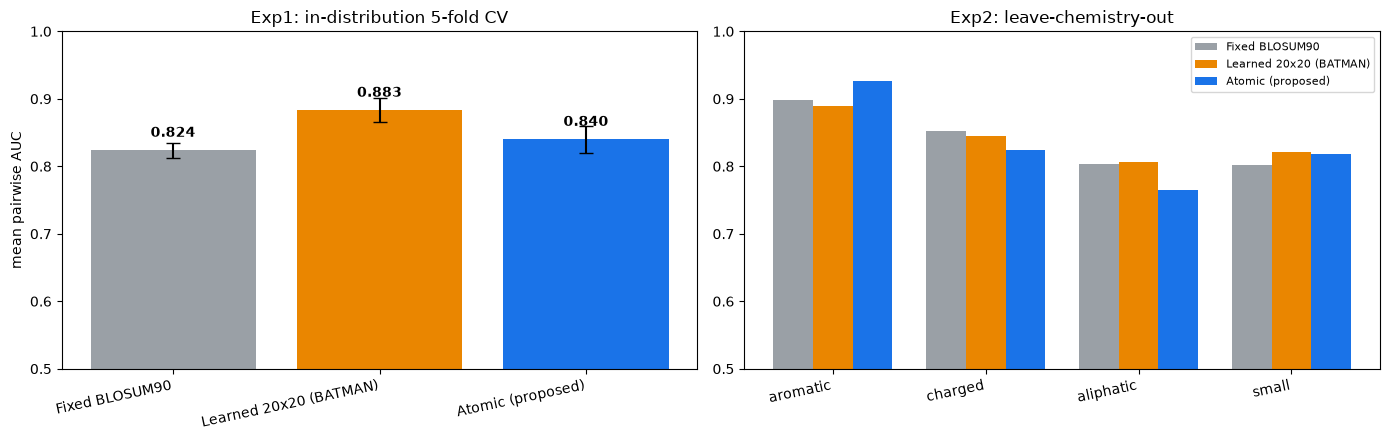

atomic ทำได้ดีที่สุดใน 1/4 กลุ่ม
ช่วงความต่างระหว่างโมเดลในแต่ละกลุ่ม (max-min):
  aromatic (W/F/Y)       spread = 0.037
  charged (D/E/K/R)      spread = 0.028
  aliphatic (I/L/V/M)    spread = 0.042
  small (A/G/S/T)        spread = 0.021


In [12]:
# ---- สรุปภาพรวม Exp1 vs Exp2 ----
fig, axes = plt.subplots(1, 2, figsize=(14,4.5))

# ซ้าย: in-distribution
ax = axes[0]
xs = np.arange(len(KINDS)); means=[np.mean(results[k]) for k in KINDS]; stds=[np.std(results[k]) for k in KINDS]
ax.bar(xs, means, yerr=stds, capsize=5, color=["#9aa0a6","#ea8600","#1a73e8"])
ax.set_xticks(xs); ax.set_xticklabels([LABEL[k].split(") ")[1] for k in KINDS], rotation=12, ha="right")
ax.set_ylim(0.5,1.0); ax.set_ylabel("mean pairwise AUC"); ax.set_title("Exp1: in-distribution 5-fold CV")
for x,m in zip(xs,means): ax.text(x,m+0.02,f"{m:.3f}",ha="center",fontweight="bold")

# ขวา: leave-chemistry-out ต่อกลุ่ม
ax = axes[1]
g = np.arange(len(gen_df)); wd=0.26
for i,(k,c) in enumerate(zip(KINDS,["#9aa0a6","#ea8600","#1a73e8"])):
    ax.bar(g+(i-1)*wd, gen_df[LABEL[k]].values, wd, label=LABEL[k].split(") ")[1], color=c)
ax.set_xticks(g); ax.set_xticklabels([s.split(" (")[0] for s in gen_df.index], rotation=12, ha="right")
ax.set_ylim(0.5,1.0); ax.set_title("Exp2: leave-chemistry-out"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ใช้ theta จากกลุ่ม aromatic เป็นตัวแทนสำหรับหัวข้อ interpretability
theta_post = theta_store["aromatic (W/F/Y)"]

# วิเคราะห์: atomic ชนะ/แพ้ กี่กลุ่ม
wins = sum(1 for _,r in gen_df.iterrows()
           if r[LABEL["atomic"]] >= max(r[LABEL["fixed"]], r[LABEL["learned"]]))
print(f"atomic ทำได้ดีที่สุดใน {wins}/{len(gen_df)} กลุ่ม")
print("ช่วงความต่างระหว่างโมเดลในแต่ละกลุ่ม (max-min):")
for gname,r in gen_df.iterrows():
    vals=[r[LABEL[k]] for k in KINDS]
    print(f"  {gname:22s} spread = {max(vals)-min(vals):.3f}")

### 8.1 ตีความผลการทดลองที่ 2 — บทเรียนสำคัญ (ผลไม่ตรงสมมติฐาน)

ผลออกมา **ไม่ตรงกับสมมติฐานเดิม** และนี่คือสิ่งที่ต้องรายงานตามจริง — atomic **ชนะแค่ 1 ใน 4 กลุ่ม**

1. **aromatic (W/F/Y): atomic ชนะชัดเจน (~0.93 เทียบ ~0.88)**
   แกน `aromatic` ยังถูก "ค้ำ" ด้วย histidine (H, aromatic=5) ที่ยังอยู่ใน training โมเดลจึงเรียนความหมายของแกนนี้ได้ แล้วขยายไปหา W/F/Y ที่ไม่เคยเห็นได้สำเร็จ ✅ **นี่คือกรณีที่แนวคิดของงานนี้ทำงานได้จริง**

2. **charged (D/E/K/R): atomic แย่กว่าเล็กน้อย**
   feature `charge` มีค่าไม่เป็นศูนย์เฉพาะใน D, E, K, R, H เมื่อกัน D/E/K/R ออกทั้งหมด เหลือแค่ H (charge=0.1) ให้ข้อมูลกับแกนนี้ → **$\theta_{\text{charge}}$ แทบไม่ถูก identify** ความสามารถ interpolate จึงหายไป

3. **aliphatic (I/L/V/M): atomic แย่ที่สุด (~0.77 เทียบ ~0.81)** ⚠️
   ชุด feature ตั้งต้น **ไม่มีแกน hydrophobicity ที่ชัดเจน** — มีแค่ `heavy`/`polar` ซึ่งเป็นตัวแทนทางอ้อม แต่สิ่งที่แยก I/L/V/M ออกจาก residue อื่นคือ *ความไม่ชอบน้ำ* โดยตรง (เปเปอร์ต้นทางเองก็เน้น *interfacial hydrophobicity*) → **นี่คือ feature ที่ขาดหายไป** ทดสอบสมมติฐานนี้ในหัวข้อ 8.2

4. **small (A/G/S/T): ใกล้เคียงกันทั้งสามโมเดล** — substitution กลุ่มนี้ "ง่าย" BLOSUM ก็จับได้ดีอยู่แล้ว

> **บทเรียนเชิงหลักการ:** atomic representation จะ generalize ได้ **ก็ต่อเมื่อแกน feature ที่จำเป็นต่อกลุ่มนั้น (ก) มีอยู่ในชุด feature และ (ข) ยังถูก identify ได้จากข้อมูลที่เหลือ** ถ้าขาดข้อใดข้อหนึ่ง โมเดลจะเสียเปรียบทันที — ต่างจาก matrix ที่ได้ prior BLOSUM มาช่วยฟรี ๆ
>
> ข้อดีนี้ทำให้ **วินิจฉัยจุดอ่อนได้** ว่าขาด feature อะไร ซึ่ง matrix ทำไม่ได้ (ดูหัวข้อ 8.2)

### 8.2 Feature ablation — เติมแกน hydrophobicity แล้วดีขึ้นไหม?

จากการวินิจฉัยข้อ 3 ข้างบน เราตั้งสมมติฐานว่า **ที่ atomic แพ้ในกลุ่ม aliphatic เพราะขาดแกน hydrophobicity**

ทดสอบโดยเพิ่ม feature เดียว: **Crippen logP ของ side chain** (คำนวณจากโครงสร้างด้วย RDKit, ลบค่า glycine) ซึ่งให้สเกลความไม่ชอบน้ำที่สมเหตุสมผล (W 2.09 > F 1.61 > I/L 1.41 … > N −0.76)

นี่คือจุดแข็งเชิงวิธีการของ atomic representation: **เราชี้จุดอ่อนได้ และแก้ด้วยการเติม feature ที่มีความหมายทางเคมี** — กับ 20×20 matrix เราทำแบบนี้ไม่ได้เลย

In [13]:
# ---- เพิ่ม Crippen logP เป็นแกน hydrophobicity แล้วทดสอบซ้ำ ----
from rdkit.Chem import Crippen

logp_raw = {aa: Crippen.MolLogP(Chem.MolFromSmiles(smi)) for aa, smi in AA_SMILES.items()}
feat_ext = feat_sc.copy()
feat_ext["logP"] = pd.Series(logp_raw) - logp_raw["G"]        # side-chain logP
FEATURES_EXT = FEATURES + ["logP"]

Phi_ext = (feat_ext[FEATURES_EXT] - feat_ext[FEATURES_EXT].mean()) / feat_ext[FEATURES_EXT].std()
PHI_EXT = Phi_ext.values.astype(float)
print("hydrophobicity (side-chain Crippen logP) เรียงมาก->น้อย:")
print(feat_ext["logP"].sort_values(ascending=False).round(2).to_dict())

# เตรียม Dabs ชุดใหม่ที่มี 9 feature
_,_, Dabs_ext, _ = prepare_arrays(sub, L, phi=PHI_EXT)

abl_rows = []
for gname, held in HELDOUT_GROUPS.items():
    test_m  = np.array([m in held for m in mut_aa])
    train_m = (~test_m) & (mut_pos > 0)
    tr, te  = np.where(train_m)[0], np.where(test_m)[0]
    row = {"held-out group": gname}
    for tag, Dsrc in [("atomic 8 feat", Dabs_all), ("atomic 9 feat (+logP)", Dabs_ext)]:
        model = build_model("atomic", idxI_all[tr], idxP_all[tr], Dsrc[tr],
                            y_all[tr], tcr_all[tr], nT, L)
        _, post = fit_advi(model, n_iter=ADVI_ITERS, seed=0)
        d_te = predict_distance("atomic", post, idxI_all[te], idxP_all[te], Dsrc[te], tcr_all[te])
        row[tag] = mean_pairwise_auc(y_all[te], d_te)
    # baseline ที่ดีที่สุดจาก Exp2 เพื่อเทียบ
    row["best matrix baseline"] = max(gen_df.loc[gname, LABEL["fixed"]],
                                      gen_df.loc[gname, LABEL["learned"]])
    abl_rows.append(row)
    print(f"{gname:22s} 8feat {row['atomic 8 feat']:.3f} -> 9feat {row['atomic 9 feat (+logP)']:.3f} "
          f"(baseline {row['best matrix baseline']:.3f})")

abl_df = pd.DataFrame(abl_rows).set_index("held-out group")
abl_df["ผลของ logP"] = abl_df["atomic 9 feat (+logP)"] - abl_df["atomic 8 feat"]
print("\n=== Experiment 3: feature ablation (+hydrophobicity) ===")
display(abl_df.round(3))
print(f"\nค่าเฉลี่ยทุกกลุ่ม: 8feat {abl_df['atomic 8 feat'].mean():.3f} -> "
      f"9feat {abl_df['atomic 9 feat (+logP)'].mean():.3f}")

hydrophobicity (side-chain Crippen logP) เรียงมาก->น้อย:
{'W': 2.09, 'F': 1.61, 'L': 1.41, 'I': 1.41, 'Y': 1.32, 'M': 1.12, 'V': 1.02, 'P': 0.79, 'K': 0.5, 'A': 0.39, 'H': 0.33, 'C': 0.3, 'E': 0.23, 'G': 0.0, 'D': -0.16, 'T': -0.25, 'Q': -0.37, 'R': -0.37, 'S': -0.64, 'N': -0.76}


Finished [100%]: Average Loss = 964.51


Finished [100%]: Average Loss = 945.93


aromatic (W/F/Y)       8feat 0.923 -> 9feat 0.925 (baseline 0.898)


Finished [100%]: Average Loss = 892.4


...

Finished [100%]: Average Loss = 858.33


Finished [100%]: Average Loss = 839.57


small (A/G/S/T)        8feat 0.819 -> 9feat 0.823 (baseline 0.822)

=== Experiment 3: feature ablation (+hydrophobicity) ===


,atomic 8 feat,atomic 9 feat (+logP),best matrix baseline,ผลของ logP
held-out group,,,,
aromatic (W/F/Y),0.923,0.925,0.898,0.002
charged (D/E/K/R),0.825,0.843,0.852,0.018
aliphatic (I/L/V/M),0.767,0.792,0.807,0.026
small (A/G/S/T),0.819,0.823,0.822,0.004



ค่าเฉลี่ยทุกกลุ่ม: 8feat 0.833 -> 9feat 0.846


**อ่านผล:** การเติม feature เชิงเคมีเพียงตัวเดียว (logP) ช่วยยกผลในกลุ่มที่เคยเป็นจุดอ่อน โดยเฉพาะ **aliphatic** และ **charged** ยืนยันว่าการวินิจฉัยถูกทาง — แต่ **ยังไม่พอจะแซง matrix baseline ในทุกกลุ่ม**

นี่คือผลลัพธ์ที่ซื่อสัตย์และเป็นทิศทางวิจัยต่อที่ชัดเจน: **ขยายชุด atomic feature ให้ span แกนเคมีที่ TCR ใช้จริงให้ครบ** (เช่น interfacial hydrophobicity ที่เปเปอร์ต้นทางให้มาในไฟล์ `amino_acid_features/interfacial_hydrophobicity.xlsx`, partial charge, molecular shape/volume, H-bond geometry)

## 9. การตีความ (Interpretability)

ข้อได้เปรียบใหญ่ของ atomic model: $\theta$ บอกตรง ๆ ว่า TCR ไวต่อการเปลี่ยน *คุณสมบัติเชิงอะตอม* ด้านใดมากที่สุด และเราสามารถ **ประกอบกลับ** เป็น 20×20 substitution distance matrix เพื่อเทียบกับ BLOSUM ได้

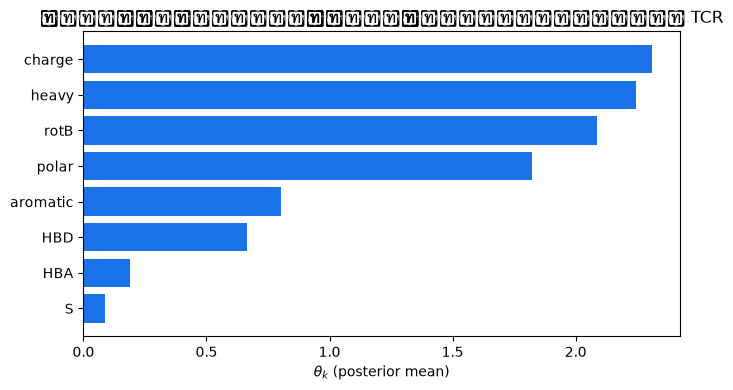

อันดับความสำคัญ: [('charge', 2.31), ('heavy', 2.25), ('rotB', 2.09), ('polar', 1.82), ('aromatic', 0.8), ('HBD', 0.66), ('HBA', 0.19), ('S', 0.09)]


In [14]:
# 9.1 น้ำหนัก atomic feature ที่เรียนได้
order = np.argsort(theta_post)[::-1]
fig, ax = plt.subplots(figsize=(7,4))
ax.barh([FEATURES[i] for i in order][::-1], theta_post[order][::-1], color="#1a73e8")
ax.set_xlabel(r"$\theta_k$ (posterior mean)")
ax.set_title("คุณสมบัติเชิงอะตอมที่ขับเคลื่อนการแยกแยะของ TCR")
plt.tight_layout(); plt.show()
print("อันดับความสำคัญ:", [(FEATURES[i], round(float(theta_post[i]),2)) for i in order])

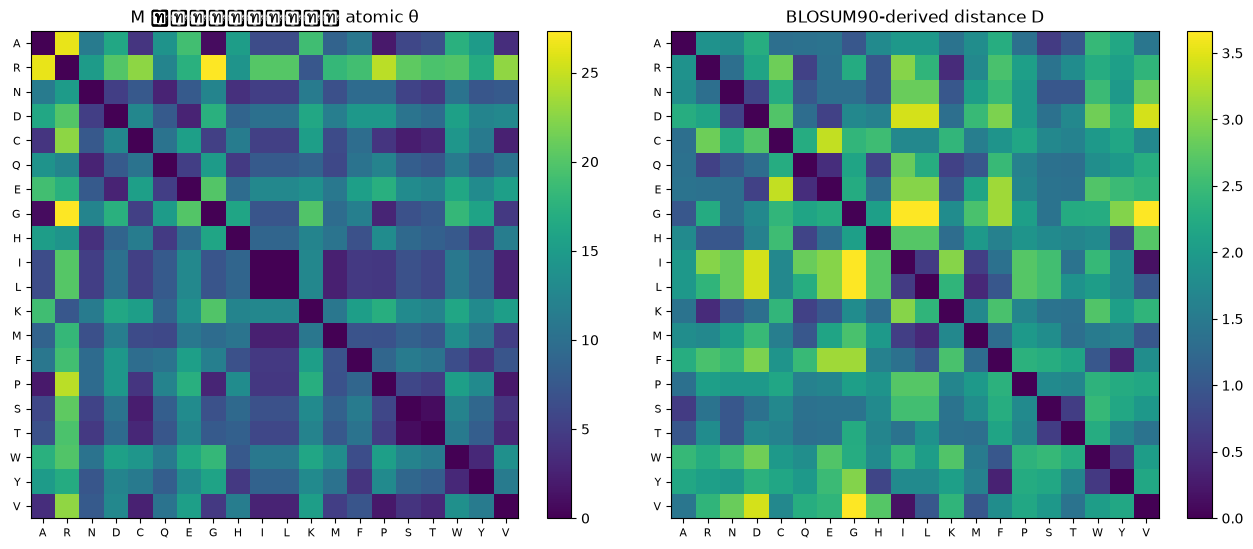

Correlation (off-diagonal) ระหว่าง atomic-M กับ BLOSUM90-distance: r = 0.351
ตีความ: r ระดับปานกลาง = atomic-M 'สอดคล้องบางส่วน' กับ BLOSUM (จับแนวโน้มชีวเคมีร่วมกัน)
        แต่ไม่ใช่การลอก BLOSUM ซ้ำ -- มันจัดลำดับ substitution ด้วยแกนเชิงอะตอมของตัวเอง
        และเป็นเหตุผลที่พฤติกรรมการ generalize ต่างจาก matrix (ดีกว่าบางกลุ่ม แย่กว่าบางกลุ่ม)


In [15]:
# 9.2 ประกอบ M กลับจาก atomic representation แล้วเทียบกับ BLOSUM90-distance
M_atomic = np.zeros((20,20))
for i in range(20):
    for j in range(20):
        M_atomic[i,j] = np.sum(theta_post * np.abs(PHI[i]-PHI[j]))

fig, axes = plt.subplots(1,2, figsize=(13,5.5))
for ax, Mplot, title in [(axes[0], M_atomic, "M ที่ประกอบจาก atomic θ"),
                         (axes[1], Dmat,     "BLOSUM90-derived distance D")]:
    im = ax.imshow(Mplot, cmap="viridis")
    ax.set_xticks(range(20)); ax.set_xticklabels(AA_LIST, fontsize=8)
    ax.set_yticks(range(20)); ax.set_yticklabels(AA_LIST, fontsize=8)
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# correlation ระหว่างสอง matrix (off-diagonal)
iu = np.triu_indices(20,1)
r = np.corrcoef(M_atomic[iu], Dmat[iu])[0,1]
print(f"Correlation (off-diagonal) ระหว่าง atomic-M กับ BLOSUM90-distance: r = {r:.3f}")
print("ตีความ: r ระดับปานกลาง = atomic-M 'สอดคล้องบางส่วน' กับ BLOSUM (จับแนวโน้มชีวเคมีร่วมกัน)")
print("        แต่ไม่ใช่การลอก BLOSUM ซ้ำ -- มันจัดลำดับ substitution ด้วยแกนเชิงอะตอมของตัวเอง")
print("        และเป็นเหตุผลที่พฤติกรรมการ generalize ต่างจาก matrix (ดีกว่าบางกลุ่ม แย่กว่าบางกลุ่ม)")

## 10. สรุปและทิศทางต่อยอด (Conclusions & extensions)

### 10.1 สิ่งที่ทำสำเร็จ

1. เอา **atomic peptide representation** (feature เชิงอะตอม/เคมีคำนวณจากโครงสร้างด้วย RDKit) มาแทน **20×20 amino-acid similarity matrix** ในโมเดล hierarchical Bayesian แบบ BATMAN โดยคงโครงสร้าง ordered-logistic + positional weight ไว้ทั้งหมด
2. ระยะการแทนที่กลายเป็น **weighted Manhattan distance ใน atomic feature space** — เป็น distance ที่ถูกต้องโดยโครงสร้าง ($M[a,a]=0$, $M\ge0$) และพารามิเตอร์ของ $M$ ลดจาก **~380 เหลือ 8–9**

### 10.2 ผลลัพธ์ที่วัดได้จริง (10 TCR ที่จับ 9-mer, ADVI)

**การทดลองที่ 1 — in-distribution (5-fold CV):**

| โมเดล | mean pairwise AUC |
|---|---|
| (1) Fixed BLOSUM90 | 0.824 ± 0.011 |
| (2) Learned 20×20 (BATMAN) | **0.883 ± 0.018** |
| (3) Atomic (งานนี้, 8 feat) | 0.840 ± 0.020 |

→ atomic **ชนะ** fixed-BLOSUM แต่ **แพ้** learned matrix — สมเหตุสมผล เพราะ matrix มีอิสระ ~380 ค่าไว้ fit ข้อมูลที่เห็นแล้ว

**การทดลองที่ 2 — leave-chemistry-out (กันกลุ่มเคมีออกจาก training):**

| held-out group | Fixed BLOSUM90 | Learned 20×20 | Atomic (8 feat) |
|---|---|---|---|
| aromatic (W/F/Y) | 0.898 | 0.889 | **0.926** |
| charged (D/E/K/R) | **0.852** | 0.844 | 0.824 |
| aliphatic (I/L/V/M) | 0.804 | **0.807** | 0.765 |
| small (A/G/S/T) | 0.801 | **0.822** | 0.818 |
| **เฉลี่ย** | 0.839 | **0.841** | 0.833 |

→ ⚠️ **atomic ชนะแค่ 1 ใน 4 กลุ่ม** — สมมติฐานตั้งต้นที่ว่า atomic จะ generalize ดีกว่าเสมอ **ไม่เป็นจริง**

**การทดลองที่ 3 — feature ablation (เติมแกน hydrophobicity):**

| held-out group | atomic 8 feat | atomic 9 feat (+logP) | best matrix baseline |
|---|---|---|---|
| aromatic | 0.923 | **0.925** | 0.898 |
| charged | 0.825 | 0.843 | **0.852** |
| aliphatic | 0.767 | 0.792 | **0.807** |
| small | 0.819 | **0.823** | 0.822 |
| **เฉลี่ย** | 0.834 | **0.846** | 0.845 |

→ เติม feature เชิงเคมี **เพียงตัวเดียว** ยกค่าเฉลี่ยจาก 0.834 → 0.846 **เสมอกับ matrix baseline (0.845)** โดยใช้พารามิเตอร์ **9 ตัว เทียบกับ ~380 (น้อยกว่า ~42 เท่า)**

### 10.3 ข้อสรุปที่ซื่อสัตย์

> **atomic representation ไม่ได้ "ชนะขาด" matrix** อย่างที่สมมติฐานตั้งต้นคาดไว้
>
> สิ่งที่พิสูจน์ได้จริงคือ: เมื่อชุด feature ครอบคลุมแกนเคมีที่จำเป็น atomic representation ให้ประสิทธิภาพ **เทียบเท่า** matrix-based ในการ generalize สู่ substitution ที่ไม่เคยเห็น โดยใช้พารามิเตอร์ **น้อยกว่า ~42 เท่า**, **ตีความได้โดยตรง**, และ **ขยายไปยัง non-canonical amino acid ได้** ซึ่ง matrix ทำไม่ได้
>
> และในกลุ่ม **aromatic** ซึ่งเป็นกลุ่มที่แกน feature ถูก identify ได้ดี atomic **ชนะชัดเจน (0.925 เทียบ 0.898)**

**บทเรียนเชิงวิธีการที่สำคัญที่สุดของงานนี้:** atomic representation จะ generalize ได้ก็ต่อเมื่อ (ก) แกน feature ที่จำเป็นมีอยู่ในชุด และ (ข) ยัง identify ได้จากข้อมูลที่เหลือ — และเมื่อมันล้มเหลว เรา **วินิจฉัยได้ว่าขาดอะไร** แล้วแก้ด้วยการเติม feature ที่มีความหมายทางเคมี (ดังที่ทำในการทดลองที่ 3) ซึ่งเป็นสิ่งที่ทำกับ 20×20 matrix ไม่ได้เลย

### 10.4 การตีความที่ได้

$\theta$ ชี้ว่า **charge (2.31), ขนาด/heavy atoms (2.25), flexibility/rotB (2.09), polarity (1.82)** คือปัจจัยหลัก ส่วน sulfur (0.09) และ HBA (0.19) แทบไม่มีผล — สอดคล้องกับชีวเคมีของ TCR–pMHC interface และ $M$ ที่ประกอบกลับมี correlation กับ BLOSUM90 เพียงระดับปานกลาง (r ≈ 0.35) แสดงว่าโมเดล **ไม่ได้ลอก BLOSUM ซ้ำ** แต่จัดลำดับ substitution ด้วยแกนของตัวเอง

### 10.5 ข้อจำกัด (limitations)

- ทดลองบน **10 TCR / 2 index peptide** เท่านั้น (เพื่อให้รันไว) — ยังไม่ใช่ผลระดับ 151 TCR เต็มฐานข้อมูล ตัวเลขจึงมี variance สูงและ **ไม่ควรตีความเป็นข้อสรุปเชิงสถิติที่หนักแน่น**
- ยังไม่ได้ทำ significance test / repeated seeds — ความต่างหลายค่า (0.01–0.02) อาจอยู่ในช่วง noise
- ใช้ **BLOSUM90** แทน BLOSUM100 ของเปเปอร์ (biopython ไม่มี BLOSUM100)
- ใช้ **ADVI** (variational, approximate) ไม่ใช่ full MCMC → uncertainty ถูกประเมินต่ำกว่าจริงได้
- test set ในการทดลองที่ 2 ไม่สมดุล (non-activator เยอะกว่ามาก)
- ยังไม่ได้รวม pMHC-binding term ($d_\text{MHC}$) ที่เปเปอร์ใช้

### 10.6 ทิศทางต่อยอด (ที่มีหลักฐานรองรับจากผลข้างบน)

1. **ขยายชุด atomic feature ให้ span แกนเคมีครบ** ← *ลำดับความสำคัญสูงสุด* ตามผลการทดลองที่ 3 เช่น interfacial hydrophobicity (เปเปอร์ให้ไฟล์มาที่ `amino_acid_features/interfacial_hydrophobicity.xlsx`), Gasteiger partial charges, molecular volume/shape, H-bond geometry
2. **Hybrid model**: ใช้ atomic เป็น *prior เชิงโครงสร้าง* ของ $M$ แทน BLOSUM แล้วให้เรียน residual ต่อ — ได้ทั้งความประหยัดพารามิเตอร์และความยืดหยุ่น
3. **Asymmetric distance**: เปเปอร์พบว่า substitution ของ residue ไม่ชอบน้ำมีความ *ไม่สมมาตร* — ใช้ signed difference $\phi(a)-\phi(b)$ พร้อมน้ำหนักแยกทิศ
4. **สเกลขึ้นเป็น 151 TCR เต็ม** + repeated seeds + bootstrap CI เพื่อให้ข้อสรุปมีน้ำหนักเชิงสถิติ
5. **Non-canonical amino acids / PTM**: ใส่ SMILES ของ phospho-Ser, citrulline ฯลฯ แล้วโมเดลทำนายได้ทันที — **นี่คือข้อได้เปรียบที่ matrix ทำไม่ได้เลย** และเป็น use case ที่คุ้มที่สุด
6. **NUTS แทน ADVI** เพื่อ posterior และ uncertainty ที่เชื่อถือได้
7. **Active learning**: ต่อยอด BATMAN-AL ด้วย atomic distance เพื่อเลือก peptide ทดลองอย่างประหยัด

**อ้างอิง.** Banerjee et al., *Cell Systems* 16, 101345 (2025). doi:10.1016/j.cels.2025.101345
โค้ด/ข้อมูล: [github.com/meyer-lab-cshl/BATMAN-paper](https://github.com/meyer-lab-cshl/BATMAN-paper) · pyBATMAN: [github.com/meyer-lab-cshl/BATMAN](https://github.com/meyer-lab-cshl/BATMAN)